
# MODULE 7: SIMPLE LINEAR REGRESSION (SLR)

**Student Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Dataset:** Indian Food Dataset  
**Phase:** 3

## Introduction

Simple Linear Regression is a supervised machine learning technique used to model the relationship between one independent variable and one continuous dependent variable.

The model estimates the relationship using the equation:

y = b0 + b1x

Where:
- y is the predicted dependent variable.
- x is the independent variable.
- b0 is the intercept.
- b1 is the regression coefficient.

## Objectives

1. Load and prepare the Indian Food dataset.
2. Select suitable independent and dependent variables.
3. Split the dataset into training and testing sets.
4. Train a Simple Linear Regression model.
5. Generate predictions and evaluate model performance.
6. Visualize the regression line and prediction errors.

## Evaluation Metrics

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)


MODULE 7: SIMPLE LINEAR REGRESSION

Dataset Shape: (255, 10)


,name,ingredients,diet,prep_time,cook_time,flavor_profile,course,state,region,total_time
0,Mihidana,"Besan flour, sugar, ghee",vegetarian,15,30,sweet,?,west bengal,east,45
1,Rabri,"Condensed milk, sugar, spices, nuts",vegetarian,10,45,sweet,unknown,uttar pradesh,north,55
2,Adhirasam,"Rice flour, jaggery, ghee, vegetable oil, elachi",vegetarian,10,50,sweet,dessert,west bengal,east,60
3,Anarsa,"Rice flour, jaggery, khus-khus seeds",vegetarian,10,50,sweet,dessert,maharashtra,west,60
4,Ariselu,"Rice flour, jaggery, ghee",vegetarian,15,75,sweet,dessert,andhra pradesh,south,90



Valid records: 225
Independent variable: Preparation Time
Dependent variable: Cooking Time


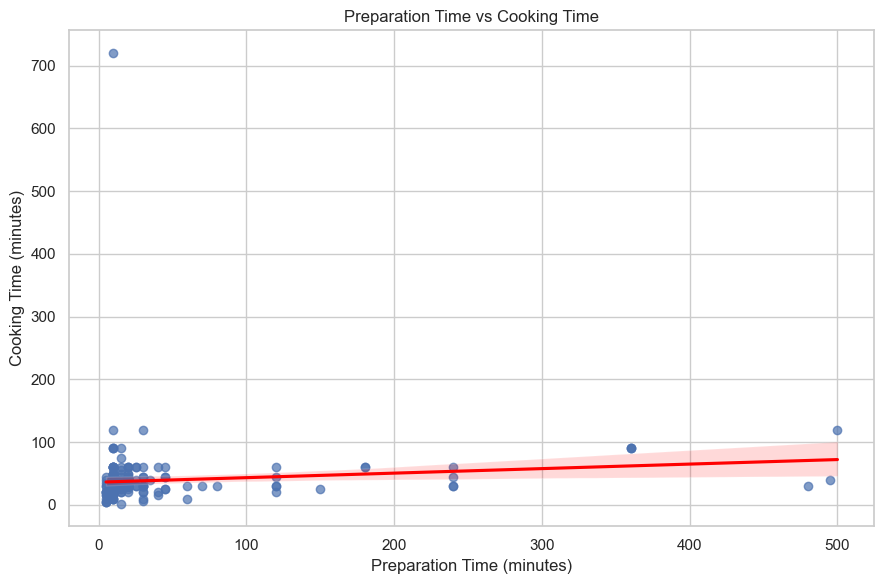


Training records: 180
Testing records: 45

Regression Intercept: 36.6567
Regression Coefficient: 0.0567

Regression Equation:
Predicted Cooking Time = 36.6567 + (0.0567 × Preparation Time)

Sample Predictions:


,Actual Cooking Time,Predicted Cooking Time,Prediction Error
0,30,41.20,-11.20
1,30,37.22,-7.22
2,30,37.79,-7.79
3,90,57.08,32.92
4,40,38.08,1.92
5,20,43.46,-23.46
6,60,38.08,21.92
7,60,37.22,22.78
8,30,38.08,-8.08
9,40,37.79,2.21



MODEL EVALUATION


,Metric,Value
0,MAE,13.0201
1,MSE,274.7187
2,RMSE,16.5746
3,R²,0.1970



Interpretation:
MAE: Predictions differ from actual cooking time by about 13.02 minutes on average.
RMSE: Typical prediction error scale is approximately 16.57 minutes, with larger errors penalized more heavily.
R²: 0.1970
The model explains only a small proportion of the variation in cooking time.


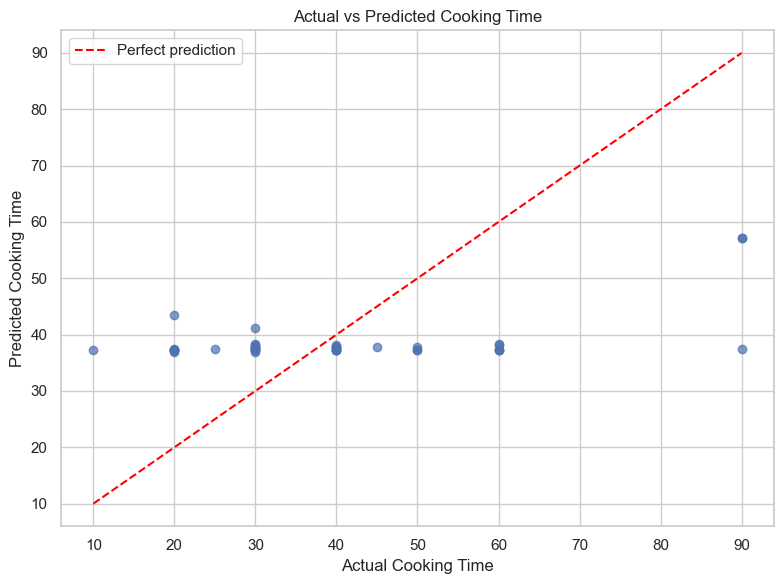

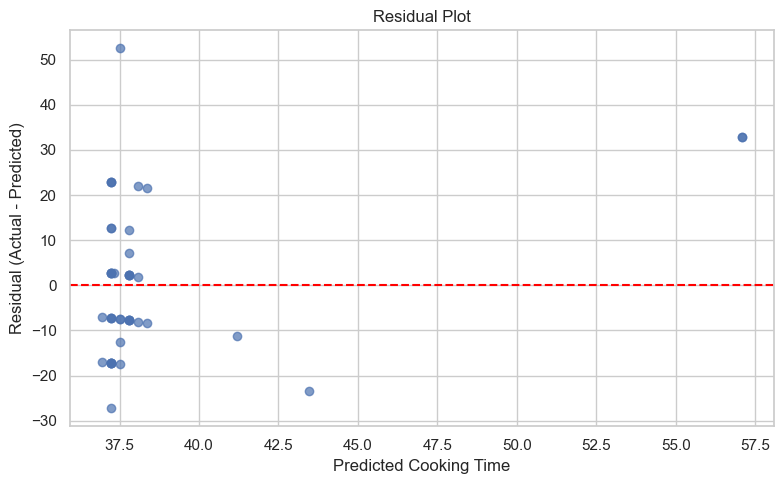


Prediction results saved to:
indian_food_slr_predictions.csv

MODULE 7 COMPLETED SUCCESSFULLY


In [1]:

# ==========================================================
# MODULE 7: SIMPLE LINEAR REGRESSION (SLR)
# Student: ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset: Indian Food
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

# ----------------------------------------------------------
# 1. LOAD DATASET
# ----------------------------------------------------------

file_path = "../Phase 1/indian_food_cleaned.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Dataset not found. Ensure this notebook is inside "
        "'Phase 3' and the CSV is inside 'Phase 1'."
    )

df = pd.read_csv(file_path)

print("=" * 60)
print("MODULE 7: SIMPLE LINEAR REGRESSION")
print("=" * 60)

print("\nDataset Shape:", df.shape)
display(df.head())

# ----------------------------------------------------------
# 2. SELECT REGRESSION VARIABLES
# Independent variable (X): prep_time
# Dependent variable (y): cook_time
# ----------------------------------------------------------

required_columns = ["prep_time", "cook_time"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

data = df[required_columns].copy()

data["prep_time"] = pd.to_numeric(
    data["prep_time"], errors="coerce"
)
data["cook_time"] = pd.to_numeric(
    data["cook_time"], errors="coerce"
)

# Remove missing and invalid time values
data = data.dropna()
data = data[
    (data["prep_time"] >= 0) &
    (data["cook_time"] >= 0)
]

# Exclude special unknown-time markers if present
data = data[
    (data["prep_time"] != -1) &
    (data["cook_time"] != -1)
]

# Require sufficient observations and variation
if len(data) < 10:
    raise ValueError(
        "Not enough valid records for regression."
    )

if data["prep_time"].nunique() < 2:
    raise ValueError(
        "The independent variable must contain variation."
    )

print("\nValid records:", len(data))
print("Independent variable: Preparation Time")
print("Dependent variable: Cooking Time")

# ----------------------------------------------------------
# 3. VISUALIZE THE RELATIONSHIP
# ----------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.regplot(
    data=data,
    x="prep_time",
    y="cook_time",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("Preparation Time vs Cooking Time")
plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Cooking Time (minutes)")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 4. TRAIN-TEST SPLIT
# ----------------------------------------------------------

X = data[["prep_time"]]
y = data["cook_time"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# ----------------------------------------------------------
# 5. TRAIN THE SIMPLE LINEAR REGRESSION MODEL
# ----------------------------------------------------------

model = LinearRegression()
model.fit(X_train, y_train)

print("\nRegression Intercept:", round(model.intercept_, 4))
print("Regression Coefficient:", round(model.coef_[0], 4))

print(
    "\nRegression Equation:\n"
    f"Predicted Cooking Time = "
    f"{model.intercept_:.4f} + "
    f"({model.coef_[0]:.4f} × Preparation Time)"
)

# ----------------------------------------------------------
# 6. MAKE PREDICTIONS
# ----------------------------------------------------------

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Cooking Time": y_test.to_numpy(),
    "Predicted Cooking Time": y_pred
})

results["Prediction Error"] = (
    results["Actual Cooking Time"] -
    results["Predicted Cooking Time"]
)

print("\nSample Predictions:")
display(results.head(10).round(2))

# ----------------------------------------------------------
# 7. EVALUATE THE MODEL
# ----------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Value": [mae, mse, rmse, r2]
})

print("\nMODEL EVALUATION")
display(metrics.round(4))

print(
    "\nInterpretation:"
    f"\nMAE: Predictions differ from actual cooking time by "
    f"about {mae:.2f} minutes on average."
    f"\nRMSE: Typical prediction error scale is "
    f"approximately {rmse:.2f} minutes, with larger errors "
    "penalized more heavily."
    f"\nR²: {r2:.4f}"
)

if r2 < 0:
    print(
        "The model performs worse than predicting the test-set "
        "mean for every record."
    )
elif r2 < 0.30:
    print(
        "The model explains only a small proportion of the "
        "variation in cooking time."
    )
else:
    print(
        "The model explains a measurable proportion of the "
        "variation in cooking time."
    )

# ----------------------------------------------------------
# 8. ACTUAL VS PREDICTED PLOT
# ----------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual Cooking Time")
plt.ylabel("Predicted Cooking Time")
plt.title("Actual vs Predicted Cooking Time")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 9. RESIDUAL ANALYSIS
# ----------------------------------------------------------

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--", color="red")

plt.xlabel("Predicted Cooking Time")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 10. SAVE PREDICTION RESULTS
# ----------------------------------------------------------

results.to_csv(
    "indian_food_slr_predictions.csv",
    index=False
)

print("\nPrediction results saved to:")
print("indian_food_slr_predictions.csv")

print("\nMODULE 7 COMPLETED SUCCESSFULLY")



## Conclusion

Simple Linear Regression was applied to the Indian Food dataset to study the relationship between preparation time and cooking time.

The dataset was cleaned for missing and invalid time values, divided into training and testing sets, and used to train a regression model.

The model was evaluated using MAE, MSE, RMSE, and R². Actual-versus-predicted and residual plots were generated to assess the predictions and identify possible model limitations.

The regression coefficient indicates the estimated change in cooking time associated with a one-minute increase in preparation time. The evaluation results show how well preparation time alone explains cooking-time variation.

Since recipe preparation and cooking durations can depend on ingredients, cooking methods, recipe complexity, and other factors, a single-variable model may have limited predictive performance.
